In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 40)

# ---- Paths ----------------------------------------------------------------
RAW_CSV = "Medicare_Physician_Other_Practitioners_by_Provider_and_Service_2024.csv"
OUT_PARQUET = "data/processed/peer_features.parquet"
OUT_DICT = "data/processed/peer_features_dictionary.csv"

# ---- Choices --------------------------------------------------------------
SEED = 42
DEV_SAMPLE_FRAC = None
MIN_GROUP = 100   # minimum rows for a peer group to be used (team setting; see the trade-off table at the end)

# Peer levels, most specific first. A row uses the first level whose group has >= MIN_GROUP rows.
PEER_LEVELS = {1: ["Rndrng_Prvdr_Type", "HCPCS_Cd", "Place_Of_Srvc"],
               2: ["HCPCS_Cd", "Place_Of_Srvc"],
               3: ["HCPCS_Cd"]}

# Four final features: name -> source column. Each is log1p-transformed, then scored inside its peer group.
FEATURES = {"log_pay": "Avg_Mdcr_Stdzd_Amt",          # Medicare standardized payment
            "log_benes": "Tot_Benes",                 # volume (patients)
            "log_srvcs_per_bene": "srvcs_per_bene",   # services per patient = Tot_Srvcs / Tot_Benes
            "log_markup": "chrg_to_alowd"}            # billed vs allowed = Avg_Sbmtd_Chrg / Avg_Mdcr_Alowd_Amt

MILEAGE_CODES = ["A0425", "A0435", "A0436", "P9603"]   # Tot_Srvcs = miles, not visits

## A1. Load and clean
**What:** keep U.S. providers, drop rows that are logically impossible, and tag each row with a `segment`.

**Why `segment` matters:** `Tot_Srvcs` is a count of *visits* for regular services, *billing units* for drugs, and *miles* for ambulance mileage codes. Comparing those units against each other would be meaningless. Every peer level contains the HCPCS code, so peers always share a segment; `segment` is kept as a descriptive tag for the checks below.

Impossible rows are those where services < beneficiaries, beneficiary-days > services, or the allowed amount is $0.

In [2]:
usecols = ["Rndrng_NPI", "Rndrng_Prvdr_Type", "Rndrng_Prvdr_Ent_Cd", "Rndrng_Prvdr_RUCA", "Rndrng_Prvdr_Cntry",
           "HCPCS_Cd", "HCPCS_Drug_Ind", "Place_Of_Srvc",
           "Tot_Benes", "Tot_Srvcs", "Tot_Bene_Day_Srvcs",
           "Avg_Sbmtd_Chrg", "Avg_Mdcr_Alowd_Amt", "Avg_Mdcr_Stdzd_Amt"]
assert os.path.exists(RAW_CSV), f"Raw CSV not found at {RAW_CSV!r}. Set RAW_CSV in the config cell."

raw = pd.read_csv(RAW_CSV, usecols=usecols, dtype={"HCPCS_Cd": "string", "Rndrng_Prvdr_RUCA": "string"})
print(f"Loaded {len(raw):,} rows x {raw.shape[1]} columns")

Loaded 9,781,673 rows x 14 columns


In [3]:
n_raw = len(raw)
is_us = raw["Rndrng_Prvdr_Cntry"] == "US"
impossible = ((raw["Tot_Srvcs"] < raw["Tot_Benes"]) |
              (raw["Tot_Bene_Day_Srvcs"] > raw["Tot_Srvcs"]) |
              (raw["Avg_Mdcr_Alowd_Amt"] <= 0))
n_foreign, n_impossible = int((~is_us).sum()), int((is_us & impossible).sum())

df = raw[is_us & ~impossible].reset_index(drop=True)
del raw

df["row_id"] = np.arange(len(df), dtype="int64")          # position after cleaning
df["segment"] = np.where(df["HCPCS_Drug_Ind"].eq("Y"), "drug",
                 np.where(df["HCPCS_Cd"].isin(MILEAGE_CODES), "mileage", "service"))
df["Rndrng_Prvdr_RUCA"] = df["Rndrng_Prvdr_RUCA"].fillna("unknown")   # missing RUCA -> explicit category

# Two ratio features
df["srvcs_per_bene"] = df["Tot_Srvcs"] / df["Tot_Benes"]
df["chrg_to_alowd"]  = df["Avg_Sbmtd_Chrg"] / df["Avg_Mdcr_Alowd_Amt"]

if DEV_SAMPLE_FRAC:   # keep whole providers so their rows stay together
    keep = df["Rndrng_NPI"].drop_duplicates().sample(frac=DEV_SAMPLE_FRAC, random_state=SEED)
    df = df[df["Rndrng_NPI"].isin(keep)].reset_index(drop=True)
    df["row_id"] = np.arange(len(df), dtype="int64")

for c in sorted({c for cols in PEER_LEVELS.values() for c in cols} | {"segment"}):
    df[c] = df[c].astype("category")

summary = pd.DataFrame({"rows": [n_raw, -n_foreign, -n_impossible, len(df)]},
                       index=["raw file", "foreign providers removed", "impossible values removed", "kept"])
summary["pct_of_raw"] = (summary["rows"] / n_raw * 100).round(4)
display(summary)
display(df["segment"].value_counts().to_frame("rows"))

,rows,pct_of_raw
raw file,9781673,100.0000
foreign providers removed,-422,-0.0043
impossible values removed,-90,-0.0009
kept,9781161,99.9948


,rows
segment,
service,9241898
drug,529570
mileage,9693


**Takeaway:** the CMS file is already very clean. Removed only **512 of 9,781,673 rows (about 0.005%)**: 422 foreign providers and 90 impossible rows. The split was about 9.24M `service`, 530K `drug` and 9.7K `mileage` rows.

## A2. Peer-group sizes and fallback logic
**What:** a z-score only means something if the group it is computed in is big enough. Before computing any features we measure the groups.

- **Level 1:** Provider Type × HCPCS × Place of Service (most comparable, but many small groups)
- **Level 2 fallback:** HCPCS × Place of Service
- **Level 3 fallback:** HCPCS

**Rule:** each row uses the most specific level whose group has at least `MIN_GROUP` (100) rows. If none of the three is big enough, the row is **unscored**, with no reliable peer group. HCPCS is in every level, so peers always share a segment. This directly answers the challenge of peer groups that remain too small.


In [4]:
for lvl, cols in PEER_LEVELS.items():
    df[f"gid{lvl}"]     = df.groupby(cols, observed=True, sort=False).ngroup().astype("int32")
    df[f"group_n{lvl}"] = df.groupby(f"gid{lvl}")["row_id"].transform("size").astype("int32")

level_sizes = {lvl: df.groupby(f"gid{lvl}").size() for lvl in PEER_LEVELS}
for lvl, s in level_sizes.items():
    print(f"Level {lvl} ({' x '.join(PEER_LEVELS[lvl])}): {len(s):,} groups | singletons: {(s == 1).sum():,} | median size: {int(s.median())}")

fine_sizes = level_sizes[1]   # size table and plot below describe level 1
rows = []
for k in [2, 5, 10, 20, 30, 50, 100, 200]:
    small = fine_sizes < k
    rows.append({"group size <": k,
                 "% of groups": round(small.mean() * 100, 2),
                 "rows in them": int(fine_sizes[small].sum()),
                 "% of rows": round(fine_sizes[small].sum() / len(df) * 100, 2)})
size_table = pd.DataFrame(rows).set_index("group size <")
display(size_table)


Level 1 (Rndrng_Prvdr_Type x HCPCS_Cd x Place_Of_Srvc): 59,777 groups | singletons: 18,987 | median size: 3
Level 2 (HCPCS_Cd x Place_Of_Srvc): 8,939 groups | singletons: 1,419 | median size: 19
Level 3 (HCPCS_Cd): 6,471 groups | singletons: 880 | median size: 24


,% of groups,rows in them,% of rows
group size <,,,
2,31.76,18987,0.19
5,54.95,56089,0.57
10,66.50,101741,1.04
20,75.20,173146,1.77
30,79.29,231844,2.37
50,83.59,330102,3.37
100,88.35,531990,5.44
200,92.02,839932,8.59


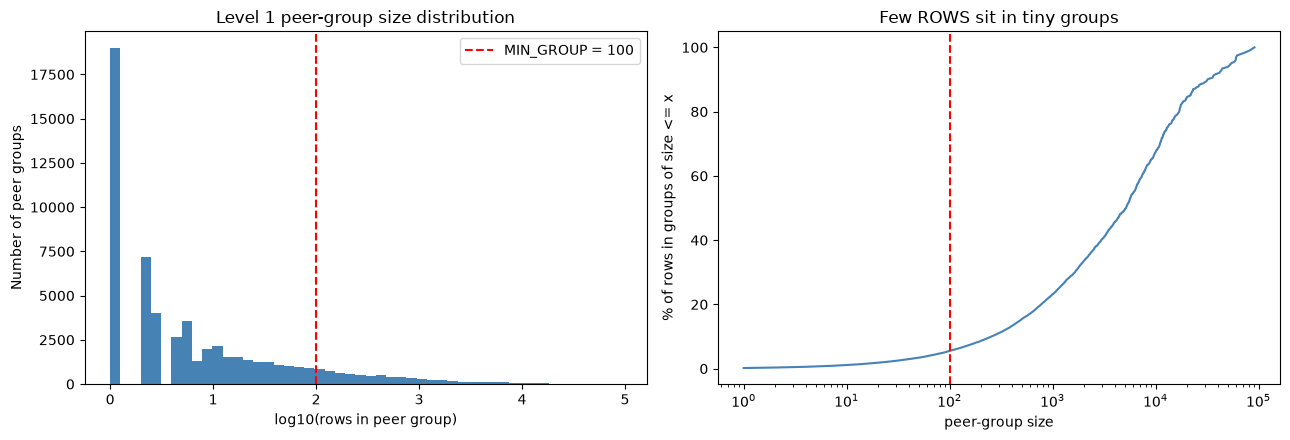

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(np.log10(fine_sizes), bins=50, color="steelblue")
axes[0].axvline(np.log10(MIN_GROUP), color="red", ls="--", label=f"MIN_GROUP = {MIN_GROUP}")
axes[0].set(xlabel="log10(rows in peer group)", ylabel="Number of peer groups", title="Level 1 peer-group size distribution")
axes[0].legend()

vc = fine_sizes.value_counts().sort_index()
share_rows = (vc.index.to_numpy() * vc.to_numpy()).cumsum() / len(df) * 100
axes[1].plot(vc.index, share_rows, color="steelblue")
axes[1].set_xscale("log")
axes[1].axvline(MIN_GROUP, color="red", ls="--")
axes[1].set(xlabel="peer-group size", ylabel="% of rows in groups of size <= x",
            title="Few ROWS sit in tiny groups")
plt.tight_layout(); plt.show()

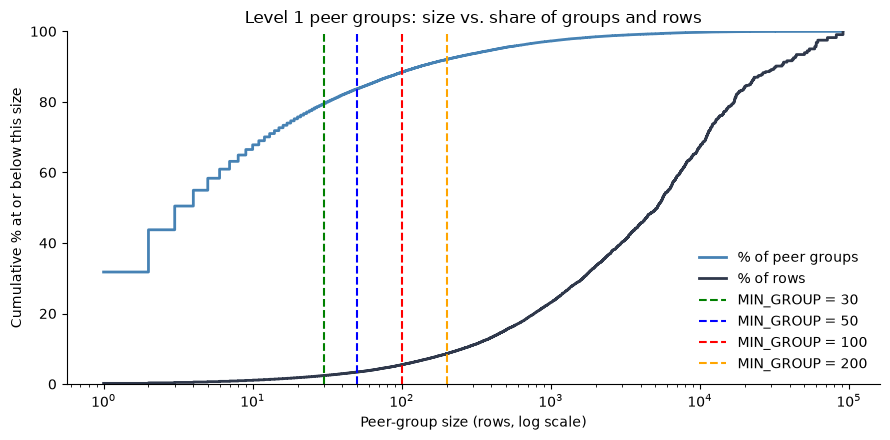

In [24]:
vc = fine_sizes.value_counts().sort_index()          # group size -> number of groups
x = vc.index.to_numpy()
pct_groups = vc.to_numpy().cumsum() / len(fine_sizes) * 100
pct_rows   = (x * vc.to_numpy()).cumsum() / len(df) * 100

small = fine_sizes < MIN_GROUP
g_pct, r_pct = small.mean() * 100, fine_sizes[small].sum() / len(df) * 100

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.step(x, pct_groups, where="post", color="steelblue", lw=2, label="% of peer groups")
ax.step(x, pct_rows,   where="post", color="#2f384b",   lw=2, label="% of rows")

ax.axvline(30, color="green", ls="--", label=f"MIN_GROUP = {30}")
ax.axvline(50, color="blue", ls="--", label=f"MIN_GROUP = {50}")
ax.axvline(MIN_GROUP, color="red", ls="--", label=f"MIN_GROUP = {MIN_GROUP}")
ax.axvline(200, color="orange", ls="--", label=f"MIN_GROUP = {200}")

ax.set_xscale("log"); ax.set_ylim(0, 100)
ax.set(xlabel="Peer-group size (rows, log scale)", ylabel="Cumulative % at or below this size",
       title="Level 1 peer groups: size vs. share of groups and rows")

ax.legend(loc="lower right", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

In [7]:
def assign_peer_level(df, min_group):
    return np.select([df["group_n1"] >= min_group, df["group_n2"] >= min_group, df["group_n3"] >= min_group],
                     [1, 2, 3], default=0).astype("int8")

df["peer_level"] = assign_peer_level(df, MIN_GROUP)
labels = {1: "1 - Type x HCPCS x POS",
          2: "2 - fallback: HCPCS x POS",
          3: "3 - fallback: HCPCS",
          0: "0 - unscored (no reliable peer group)"}
cov = df["peer_level"].map(labels).value_counts().sort_index().to_frame("rows")
cov["pct"] = (cov["rows"] / len(df) * 100).round(2)
display(cov)


,rows,pct
peer_level,,
0 - unscored (no reliable peer group),76694,0.78
1 - Type x HCPCS x POS,9249171,94.56
2 - fallback: HCPCS x POS,426925,4.36
3 - fallback: HCPCS,28371,0.29


**Takeaway:** many *groups* are tiny, but those tiny groups hold only a small share of the *rows*. In the earlier run, groups under 100 rows were 88.35% of Type × POS × HCPCS groups but only 5.44% of rows (8.59% of rows under 200). Check the coverage table above for how many rows use each level at `MIN_GROUP = 100` and how many stay unscored. For reference, the earlier two-level run at 30 had 97.63% fine, 2.36% fallback and 549 unscored rows.


## A3. Which grouping variables are worth using? (eta-squared)
**What:** eta-squared (η²) answers: *"How much of the variation in log standardized payment is explained by which group a row belongs to?"* 0 means the grouping explains nothing, 1 means it explains everything.

,candidate,groups,eta_squared,in baseline peer group?
0,HCPCS code,6471,0.9206,True
1,Provider type,113,0.1511,True
2,Drug indicator,2,0.0245,False
3,Place of service,2,0.0221,True
4,Entity type (individual/org),2,0.0083,False
5,RUCA (rural-urban),23,0.0019,False


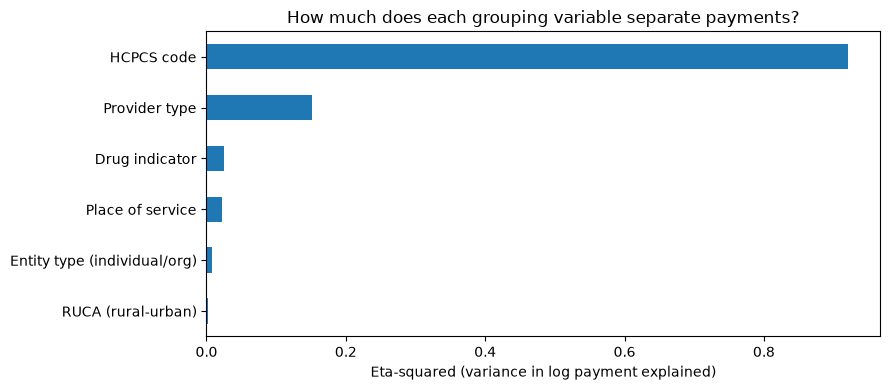

In [8]:
df["log_stdzd_payment"] = np.log1p(df["Avg_Mdcr_Stdzd_Amt"].clip(lower=0))

def eta_squared(data, group_col, target="log_stdzd_payment"):
    g = data.groupby(group_col, observed=True)[target]
    n, mean = g.size(), g.mean()
    grand = data[target].mean()
    ss_between = (n * (mean - grand) ** 2).sum()
    ss_total = ((data[target] - grand) ** 2).sum()
    return ss_between / ss_total

candidates = {"HCPCS_Cd": "HCPCS code", "Rndrng_Prvdr_Type": "Provider type", "HCPCS_Drug_Ind": "Drug indicator",
              "Place_Of_Srvc": "Place of service", "Rndrng_Prvdr_Ent_Cd": "Entity type (individual/org)",
              "Rndrng_Prvdr_State_Abrvtn": "State (not loaded here)", "Rndrng_Prvdr_RUCA": "RUCA (rural-urban)"}
eta_rows = []
for col, label in candidates.items():
    if col in df.columns:
        eta_rows.append({"candidate": label, "groups": df[col].nunique(),
                         "eta_squared": round(eta_squared(df, col), 4),
                         "in baseline peer group?": col in ("HCPCS_Cd", "Rndrng_Prvdr_Type", "Place_Of_Srvc")})
eta_df = pd.DataFrame(eta_rows).sort_values("eta_squared", ascending=False).reset_index(drop=True)
display(eta_df)

ax = eta_df.sort_values("eta_squared").plot(x="candidate", y="eta_squared", kind="barh", legend=False, figsize=(9, 4))
ax.set_xlabel("Eta-squared (variance in log payment explained)"); ax.set_ylabel("")
ax.set_title("How much does each grouping variable separate payments?")
plt.tight_layout(); plt.show()

**Takeaway:** HCPCS code explains **0.92** of payment variation and provider type **0.15**. Every *extra* candidate is tiny: drug indicator 0.025, place of service 0.022, entity type 0.008, state 0.004, RUCA 0.002. So there is **no data-driven reason to add RUCA, state or entity type** to the peer group. Alisa's independent run agrees (HCPCS 0.928, Type 0.131). Note that eta-squared is high for HCPCS partly because HCPCS has thousands of groups.

## A4. Peer-relative features
**What:** four features describe each row. Volume and payment columns are highly correlated (about 0.87-0.99), so we keep one feature per group plus two ratios. All are heavily right-skewed, so each is on the `log1p` scale.

| Feature | Source | Meaning |
|---|---|---|
| `log_pay` | `Avg_Mdcr_Stdzd_Amt` | Medicare standardized payment for the service |
| `log_benes` | `Tot_Benes` | Volume (number of patients) |
| `log_srvcs_per_bene` | `Tot_Srvcs / Tot_Benes` | Services per patient |
| `log_markup` | `Avg_Sbmtd_Chrg / Avg_Mdcr_Alowd_Amt` | How much the provider bills compared with what Medicare allows |

Every feature gets three numbers describing how far a row sits from its peers:

| Column | Meaning |
|---|---|
| `<feature>_z` | classic z-score: (x − mean) / std within the peer group |
| `<feature>_rz` | **robust** z-score: (x − median) / (1.4826 × MAD), where MAD = median(\|x − median\|). Median and MAD are not pulled around by the very outliers we are hunting |
| `<feature>_pct` | percentile rank within the peer group (0-1) |

Rows with no reliable peer group (`peer_level == 0`) get no scores. If a group's MAD is 0, the robust z is left empty (NaN) instead of dividing by zero, and we report how often that happens.


In [9]:
def peer_stats(x, gids, level):
    """z, robust z (x - median) / (1.4826 * MAD) and percentile of x inside the peer group each row is assigned to (level 1, else 2, else 3)."""
    out = {}
    for lvl, gid in gids.items():
        frame = pd.DataFrame({"x": x, "gid": gid})
        g = frame.groupby("gid")["x"]
        med = g.median()
        frame["absdev"] = np.abs(x - med.reindex(gid).to_numpy())
        mad = frame.groupby("gid")["absdev"].median()
        agg = pd.DataFrame({"mean": g.mean(), "std": g.std(), "med": med, "mad": mad})
        mean, std, med_r, mad_r = agg.reindex(gid).to_numpy().T
        with np.errstate(divide="ignore", invalid="ignore"):
            z  = (x - mean) / np.where(std > 0, std, np.nan)
            rz = (x - med_r) / np.where(mad_r > 0, 1.4826 * mad_r, np.nan)
        pct = g.rank(pct=True).to_numpy()
        out[lvl] = (z, rz, pct)
    res = [np.select([level == 1, level == 2, level == 3], [out[1][i], out[2][i], out[3][i]], default=np.nan)
           for i in range(3)]
    return [r.astype("float32") for r in res]

level = df["peer_level"].to_numpy()
gids = {lvl: df[f"gid{lvl}"].to_numpy() for lvl in PEER_LEVELS}
for name, source_col in FEATURES.items():
    x = np.log1p(df[source_col].to_numpy(dtype="float64"))
    df[name] = x.astype("float32")
    df[f"{name}_z"], df[f"{name}_rz"], df[f"{name}_pct"] = peer_stats(x, gids, level)
    print("done:", name)

rz_cols = [f"{m}_rz" for m in FEATURES]
z_cols  = [f"{m}_z"  for m in FEATURES]
scored = df["peer_level"] > 0
print(f"\nShare of scored robust-z values that are NaN because MAD = 0:")
print((df.loc[scored, rz_cols].isna().mean() * 100).round(2).to_string())


done: log_pay
done: log_benes
done: log_srvcs_per_bene
done: log_markup

Share of scored robust-z values that are NaN because MAD = 0:
log_pay_rz               10.78
log_benes_rz              0.00
log_srvcs_per_bene_rz    31.56
log_markup_rz             0.26


**Takeaway:** every scored row now has comparable "how unusual is this relative to its peers?" numbers that the models and Power BI can reuse. The NaN rates matter. If a feature is the same for most providers in a group (common for `log_srvcs_per_bene`), its MAD is 0 and its robust z cannot be computed. That is worth knowing before anyone trusts a flag on that feature.


## A5. The statistical baseline (a transparent benchmark)
**What:** a simple, explainable score the machine-learning models can be compared against.

1. For each row take the **largest absolute robust z across the four features**. This answers "how unusual is the *most* unusual thing about this row?"
2. Rank that value across all scored rows and rescale to **0–100** (`baseline_score`).
3. Flag the top **1%, 5% and 10%**.

This is a *statistical unusualness* score, **not a fraud score**. It is two-sided (unusually low is also unusual), like Isolation Forest.

In [10]:
df["baseline_raw"]   = df[rz_cols].abs().max(axis=1, skipna=True).astype("float32")
df.loc[~scored, "baseline_raw"] = np.nan
df["baseline_score"] = (df["baseline_raw"].rank(pct=True) * 100).astype("float32")
for k in (1, 5, 10):
    df[f"flag_top{k}"] = df["baseline_score"] >= (100 - k)

print("Flagged rows:", {k: int(df[f"flag_top{k}"].sum()) for k in (1, 5, 10)}, "| scored rows:", int(scored.sum()))
df.loc[scored, "baseline_score"].describe().round(2).to_frame("baseline_score")

Flagged rows: {1: 97046, 5: 485224, 10: 970448} | scored rows: 9704467


,baseline_score
count,9704467.00
mean,50.00
std,28.87
min,0.00
25%,25.00
50%,50.00
75%,75.00
max,100.00


In [11]:
# What do flagged rows look like? Median values, and ratio vs. the unflagged rest.
prof_cols = ["Tot_Benes", "Tot_Srvcs", "Avg_Sbmtd_Chrg", "Avg_Mdcr_Stdzd_Amt", "srvcs_per_bene", "chrg_to_alowd"]
profile = pd.DataFrame(index=prof_cols)
for k in (1, 5, 10):
    flagged, rest = df[f"flag_top{k}"], scored & ~df[f"flag_top{k}"]
    profile[f"median_top{k}"] = df.loc[flagged, prof_cols].median()
    profile[f"ratio_top{k}_vs_rest"] = (df.loc[flagged, prof_cols].median() / df.loc[rest, prof_cols].median()).round(2)
display(profile.round(2))

,median_top1,ratio_top1_vs_rest,median_top5,ratio_top5_vs_rest,median_top10,ratio_top10_vs_rest
Tot_Benes,26.00,0.81,26.00,0.81,30.00,0.94
Tot_Srvcs,34.00,0.77,37.00,0.84,43.00,0.98
Avg_Sbmtd_Chrg,160.60,0.90,181.45,1.01,198.00,1.12
Avg_Mdcr_Stdzd_Amt,42.56,0.81,49.41,0.94,49.84,0.94
srvcs_per_bene,1.01,0.94,1.09,1.01,1.11,1.04
chrg_to_alowd,2.87,0.97,3.00,1.01,3.15,1.06


**Takeaway:** flagged rows are not simply the biggest or most expensive. Because the score is *relative to peers*, it picks up rows that are unusual for their own specialty, service and setting.

## A6. z-score, still testing
**What:** three checks on the peer-relative scores.

1. **Classic z vs. robust z:** how many rows does each flag as extreme (|value| > 3)?
2. **Level 1 vs. fallback levels (2-3):** do the fallback groups behave like the level 1 groups?
3. **Concentration:** do extreme values pile up in a few specialties? That would signal a peer-group failure rather than real anomalies.


In [12]:
ext = pd.DataFrame({"any |z| > 3":  (df[z_cols].abs()  > 3).any(axis=1),
                    "any |rz| > 3": (df[rz_cols].abs() > 3).any(axis=1)})

print("Share of rows extreme (%), by peer level  (1 = Type x HCPCS x POS, 2-3 = fallback levels):")
display(ext[scored].groupby(df.loc[scored, "peer_level"]).mean().mul(100).round(2))

print("Share of rows extreme (%), by segment:")
display(ext[scored].groupby(df.loc[scored, "segment"], observed=True).mean().mul(100).round(2))

print("Agreement between the two definitions (scored rows, row counts):")
display(pd.crosstab(ext.loc[scored, "any |z| > 3"], ext.loc[scored, "any |rz| > 3"]))

Share of rows extreme (%), by peer level  (1 = Type x HCPCS x POS, 2-3 = fallback levels):


,any |z| > 3,any |rz| > 3
peer_level,,
1,4.11,14.01
2,6.92,22.06
3,15.64,45.67


Share of rows extreme (%), by segment:


,any |z| > 3,any |rz| > 3
segment,,
drug,4.04,15.61
mileage,2.87,6.76
service,4.28,14.39


Agreement between the two definitions (scored rows, row counts):


any |rz| > 3,False,True
any |z| > 3,,
False,8250519,1039668
True,51442,362838


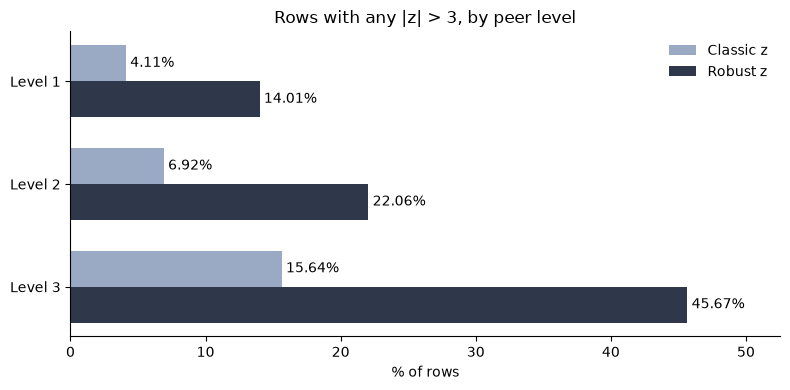

In [13]:
share = ext[scored].groupby(df.loc[scored, "peer_level"]).mean().mul(100)
levels = [f"Level {i}" for i in share.index]
y, h = np.arange(len(share)), 0.35

fig, ax = plt.subplots(figsize=(8, 4))
b1 = ax.barh(y - h/2, share["any |z| > 3"],  h, color="#9aa9c4", label="Classic z")
b2 = ax.barh(y + h/2, share["any |rz| > 3"], h, color="#2f384b", label="Robust z") 
ax.bar_label(b1, fmt="%.2f%%", padding=3)
ax.bar_label(b2, fmt="%.2f%%", padding=3)

ax.set_yticks(y, levels)
ax.invert_yaxis()                                   # Level 1 on top
ax.set_xlim(0, share.values.max() * 1.15)           # room for the labels
ax.set(xlabel="% of rows", title="Rows with any |z| > 3, by peer level")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

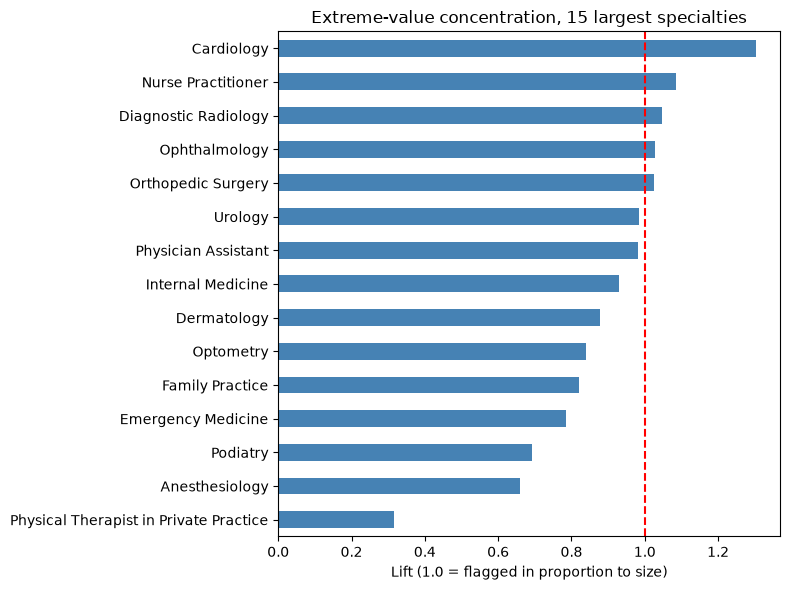

In [14]:
# Concentration: is any specialty over-represented among extreme rows?   lift = flag_share / row_share (1.0 = proportional)
flag3 = ext["any |rz| > 3"] & scored
spec = pd.DataFrame({"row_share":  df.loc[scored, "Rndrng_Prvdr_Type"].value_counts(normalize=True),
                     "flag_share": df.loc[flag3,  "Rndrng_Prvdr_Type"].value_counts(normalize=True)})
spec = spec[spec["row_share"] > 0].fillna(0)
spec["lift"] = spec["flag_share"] / spec["row_share"]
top_spec = spec.nlargest(15, "row_share").sort_values("lift")

ax = top_spec["lift"].plot(kind="barh", figsize=(8, 6), color="steelblue")
ax.axvline(1, color="red", ls="--"); ax.set(xlabel="Lift (1.0 = flagged in proportion to size)", ylabel="",
                                            title="Extreme-value concentration, 15 largest specialties")
plt.tight_layout(); plt.show()

**Takeaway:** the robust z flags more rows than the classic z because it is not inflated by outliers (earlier run, level 1 groups: 11.78% vs 4.18%). **Fallback groups looked much more "extreme"** (28.79% on robust z for the coarse fallback in that run). That is the evidence that fallback groups are less reliable and why the peer level is kept as a column, so the dashboard can show how specific the comparison group was. A specialty with a lift far from 1.0 would point to a peer-group problem rather than real anomalies. Re-run to see these checks for the three-level setup.


## A7. Fairness check: are rural or small practices unfairly flagged?
The project proposal commits to checking that poorly defined peer groups do not unfairly flag legitimate providers.

- **Raw flag rate** by RUCA (rural–urban code) and by entity type. An even spread would be 5% for the top-5% flag.
- **Observed vs. expected:** the expected rate is what we would see if the group were flagged at *its specialty's* average rate. A ratio near 1 means any difference comes from specialty mix, not location.

Flag rate (%) by entity type (I = individual, O = organization):


,pct_flagged_top5,rows
Rndrng_Prvdr_Ent_Cd,,
I,4.61,9252612
O,13.07,451855


Observed vs. expected by RUCA (look at 'rows' too; tiny groups are noisy e.g. 5.1, 8.1, 8.2, 10.3):


,obs_rate,exp_rate,rows,obs_over_exp
Rndrng_Prvdr_RUCA,,,,
1,0.049,0.050,8296922,0.987
1.1,0.049,0.052,142395,0.944
2,0.049,0.051,261903,0.963
2.1,0.055,0.057,3504,0.954
3,0.057,0.054,11101,1.061
4,0.056,0.051,597444,1.097
4.1,0.053,0.052,31108,1.011
5,0.052,0.051,50065,1.024
5.1,0.059,0.061,290,0.958


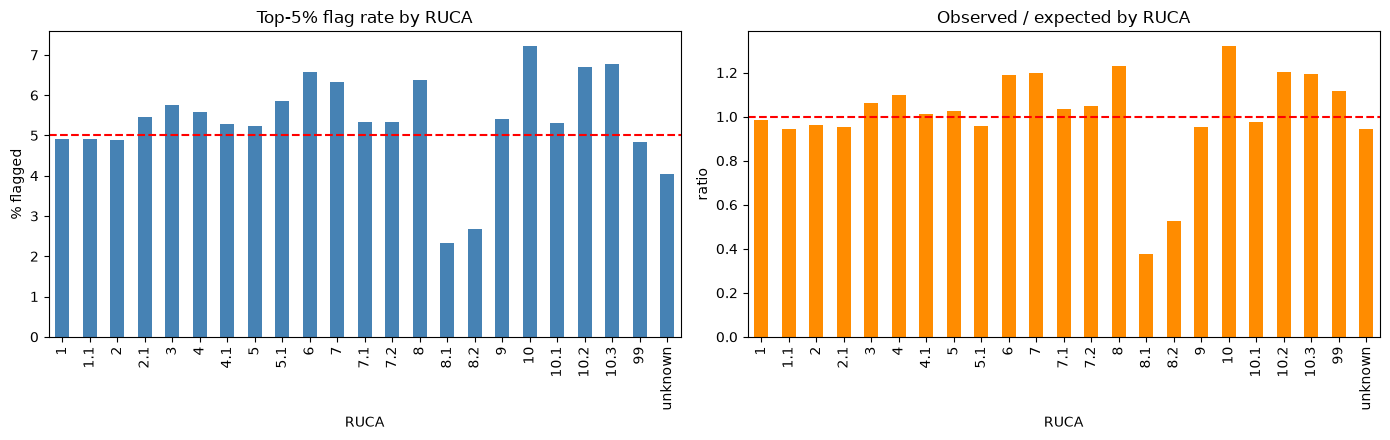

In [15]:
sc = df.loc[scored, ["segment", "Place_Of_Srvc", "Rndrng_Prvdr_Type", "Rndrng_Prvdr_RUCA",
                     "Rndrng_Prvdr_Ent_Cd", "flag_top1", "flag_top5", "flag_top10"]]

def flag_rate(by, k=5):
    r = sc.groupby(by, observed=True)[f"flag_top{k}"].agg(["mean", "size"])
    r["mean"] *= 100
    return r.rename(columns={"mean": f"pct_flagged_top{k}", "size": "rows"})

def ruca_key(v):
    n = pd.to_numeric(v, errors="coerce")
    return float("inf") if pd.isna(n) else float(n)

ruca = flag_rate("Rndrng_Prvdr_RUCA")
ruca = ruca.loc[sorted(ruca.index, key=ruca_key)]
ent = flag_rate("Rndrng_Prvdr_Ent_Cd")

sc = sc.assign(expected_top5=sc.groupby("Rndrng_Prvdr_Type", observed=True)["flag_top5"].transform("mean"))
oe = sc.groupby("Rndrng_Prvdr_RUCA", observed=True).agg(obs_rate=("flag_top5", "mean"),
                                                        exp_rate=("expected_top5", "mean"),
                                                        rows=("flag_top5", "size"))
oe["obs_over_exp"] = oe["obs_rate"] / oe["exp_rate"]
oe = oe.loc[sorted(oe.index, key=ruca_key)]

print("Flag rate (%) by entity type (I = individual, O = organization):"); display(ent.round(2))
print("Observed vs. expected by RUCA (look at 'rows' too; tiny groups are noisy e.g. 5.1, 8.1, 8.2, 10.3):"); display(oe.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
ruca["pct_flagged_top5"].plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].axhline(5, color="red", ls="--"); axes[0].set(title="Top-5% flag rate by RUCA", ylabel="% flagged", xlabel="RUCA")
oe["obs_over_exp"].plot(kind="bar", ax=axes[1], color="darkorange")
axes[1].axhline(1, color="red", ls="--"); axes[1].set(title="Observed / expected by RUCA", ylabel="ratio", xlabel="RUCA")
plt.tight_layout(); plt.show()

**Takeaway:** most RUCA groups sit close to 1.0 once specialty mix is accounted for. A few very small rural groups ran higher (earlier run: RUCA 5.1 at about 1.46 on only 290 rows).


## Provider-level behavior features
Two extra features for later explanations:

- **HCPCS concentration (HHI):** sum of squared service shares across a provider's codes. High means activity is concentrated in few services.
- **E&M mix:** share of a provider's services that are Evaluation & Management visits (HCPCS 992xx–994xx).

These are *descriptive*, used to explain a score rather than to score.

In [16]:
hcpcs_num = pd.to_numeric(df["HCPCS_Cd"], errors="coerce")
df["is_em"] = hcpcs_num.between(99200, 99499)   # 992xx, 993xx, 994xx

prov = df.assign(em_srvcs=np.where(df["is_em"], df["Tot_Srvcs"], 0.0)).groupby("Rndrng_NPI", observed=True).agg(
    total_services=("Tot_Srvcs", "sum"), em_services=("em_srvcs", "sum"), hcpcs_count=("HCPCS_Cd", "nunique"))
prov["em_mix"] = prov["em_services"] / prov["total_services"]

share = df[["Rndrng_NPI", "HCPCS_Cd", "Tot_Srvcs"]].merge(prov[["total_services"]], left_on="Rndrng_NPI", right_index=True)
share["sq"] = (share["Tot_Srvcs"] / share["total_services"]) ** 2
prov["hcpcs_hhi"] = share.groupby("Rndrng_NPI", observed=True)["sq"].sum()
display(prov[["em_mix", "hcpcs_hhi", "hcpcs_count"]].describe(percentiles=[.05, .5, .95]).round(3))

,em_mix,hcpcs_hhi,hcpcs_count
count,1207397.000,1207397.000,1207397.000
mean,0.462,0.410,7.800
std,0.405,0.274,9.764
min,0.000,0.013,1.000
5%,0.000,0.107,1.000
50%,0.453,0.327,5.000
95%,1.000,1.000,24.000
max,1.000,1.000,659.000


## Cost of each `MIN_GROUP` choice
A single table showing the *cost* of each choice using the three-level fallback logic.


,% level 1,% level 2 (HCPCS x POS),% level 3 (HCPCS),% unscored
MIN_GROUP,,,,
10,98.96,0.93,0.03,0.08
20,98.23,1.54,0.07,0.16
30,97.63,2.03,0.10,0.24
50,96.63,2.82,0.16,0.39
100,94.56,4.36,0.29,0.78
200,91.41,6.63,0.52,1.43


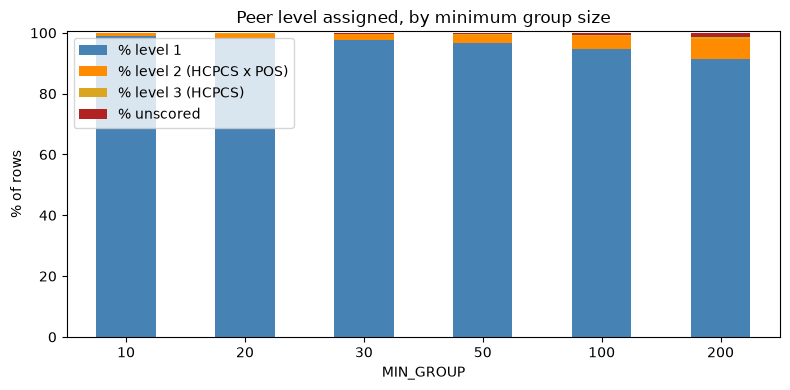

In [17]:
rows = []
for k in [10, 20, 30, 50, 100, 200]:
    lvl = assign_peer_level(df, k)
    rows.append({"MIN_GROUP": k,
                 "% level 1": round((lvl == 1).mean() * 100, 2),
                 "% level 2 (HCPCS x POS)": round((lvl == 2).mean() * 100, 2),
                 "% level 3 (HCPCS)": round((lvl == 3).mean() * 100, 2),
                 "% unscored": round((lvl == 0).mean() * 100, 2)})
tradeoff = pd.DataFrame(rows).set_index("MIN_GROUP")
display(tradeoff)

ax = tradeoff.plot(kind="bar", stacked=True, figsize=(8, 4),
                   color=["steelblue", "darkorange", "goldenrod", "firebrick"])
ax.set(ylabel="% of rows", title="Peer level assigned, by minimum group size"); ax.set_ylim(0, 100.5)
plt.xticks(rotation=0); plt.tight_layout(); plt.show()


**How to read it:** a larger `MIN_GROUP` makes each group's statistics more stable. The cost is that more rows are pushed down to the less-specific fallback levels, and the fallback groups look more "extreme"
